In [4]:
import pandas as pd

# load the raw titanic data
df = pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv")
print("Rows:", len(df), "| Columns:", df.shape[1])

# count missing values in each column
missing = df.isnull().sum()
summary = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": (missing / len(df) * 100).round(2),
    "non_missing": df.notnull().sum(),
    "data_type": df.dtypes
}).sort_values("missing_count", ascending=False)

summary.to_csv("missing_value_summary.csv")
summary

Rows: 891 | Columns: 12


,missing_count,missing_percent,non_missing,data_type
Cabin,687,77.10,204,object
Age,177,19.87,714,float64
Embarked,2,0.22,889,object
PassengerId,0,0.00,891,int64
Name,0,0.00,891,object
Pclass,0,0.00,891,int64
Survived,0,0.00,891,int64
Sex,0,0.00,891,object
Parch,0,0.00,891,int64
SibSp,0,0.00,891,int64


In [5]:
flags = df.assign(Age_missing=df["Age"].isnull(), Cabin_missing=df["Cabin"].isnull())

print("Missing count by passenger class:")
print(flags.groupby("Pclass")[["Age_missing", "Cabin_missing"]].sum())

print("\nMissing percent by passenger class:")
print((flags.groupby("Pclass")[["Age_missing", "Cabin_missing"]].mean() * 100).round(1))

print("\nPassengers with missing Embarked:")
print(df[df["Embarked"].isnull()][["Pclass", "Sex", "Fare", "Ticket"]])


Missing count by passenger class:
        Age_missing  Cabin_missing
Pclass                            
1                30             40
2                11            168
3               136            479

Missing percent by passenger class:
        Age_missing  Cabin_missing
Pclass                            
1              13.9           18.5
2               6.0           91.3
3              27.7           97.6

Passengers with missing Embarked:
     Pclass     Sex  Fare  Ticket
61        1  female  80.0  113572
829       1  female  80.0  113572


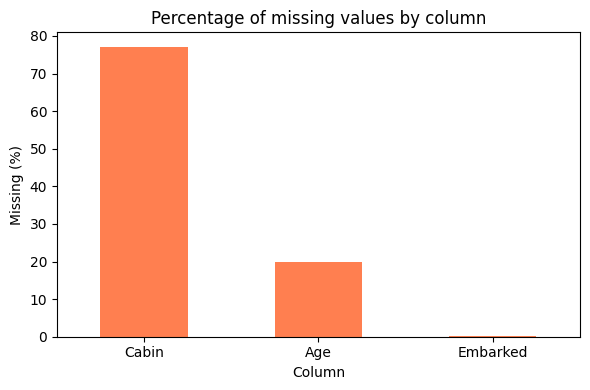

In [6]:
import matplotlib.pyplot as plt

with_missing = summary[summary["missing_count"] > 0]
ax = with_missing["missing_percent"].plot(kind="bar", color="coral", figsize=(6, 4))
ax.set_title("Percentage of missing values by column")
ax.set_xlabel("Column")
ax.set_ylabel("Missing (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("missing_values_chart.png")
plt.show()

Short findings

Only 3 of the 12 columns have missing values: Cabin (687, 77.10%), Age (177, 19.87%) and Embarked (2, 0.22%). The other 9 columns are complete.
Cabin is almost empty. It is missing for nearly all 2nd class (91.3%) and 3rd class (97.6%) passengers, but only 18.5% of 1st class passengers. So the missing values are not random.
Age is missing for about 1 in 5 passengers, most often in 3rd class (27.7%).
Embarked has only 2 missing values, too few to matter for most analysis.
I did not delete anything. Deleting 177 rows for Age would remove 20% of the data and could bias the results. I would fill Age with the median, drop or relabel Cabin, and fill Embarked with the most common value.